---
title: "EDA Demo: Wine Reviews"
subtitle: "DS 2023 | Communicating with Data"
---

## Overview

Load the dataset, inspect its structure, and look at the first six rows.

## Set up

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import panel as pn

In [2]:
sns.set_style('white')

In [3]:
data_url = "https://virginia.box.com/shared/static/eqpwseity23af9la6ppowkgv2ho4rvmz.csv"
reviews = pd.read_csv(data_url).set_index("obs_id")
reviews.info()   
reviews.head()

<class 'pandas.DataFrame'>
RangeIndex: 129971 entries, 0 to 129970
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   title     129971 non-null  str    
 1   country   129908 non-null  str    
 2   province  129908 non-null  str    
 3   variety   129970 non-null  str    
 4   taster    103727 non-null  str    
 5   price     120975 non-null  float64
 6   points    129971 non-null  int64  
 7   content   129971 non-null  str    
dtypes: float64(1), int64(1), str(6)
memory usage: 54.5 MB


,title,country,province,variety,taster,price,points,content
obs_id,,,,,,,,
0,Nicosia 2013 Vulkà Bianco (Etna) Vulkà Bianc...,Italy,Sicily & Sardinia,White Blend,Kerin O’Keefe,NaN,87,"Aromas include tropical fruit, broom, brimston..."
1,Quinta dos Avidagos 2011 Avidagos Red (Douro)...,Portugal,Douro,Portuguese Red,Roger Voss,15.0,87,"This is ripe and fruity, a wine that is smooth..."
2,Rainstorm 2013 Pinot Gris (Willamette Valley)...,US,Oregon,Pinot Gris,Paul Gregutt,14.0,87,"Tart and snappy, the flavors of lime flesh and..."
3,St. Julian 2013 Reserve Late Harvest Riesling...,US,Michigan,Riesling,Alexander Peartree,13.0,87,"Pineapple rind, lemon pith and orange blossom ..."
4,Sweet Cheeks 2012 Vintner's Reserve Wild Chil...,US,Oregon,Pinot Noir,Paul Gregutt,65.0,87,"Much like the regular bottling from 2012, this..."


Review nulls

In [4]:
# pip install missingno

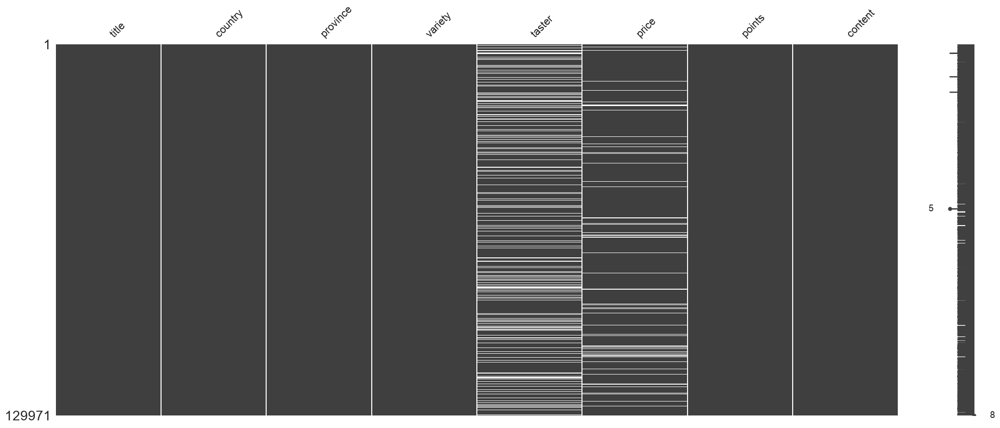

In [5]:
import missingno as msno

msno.matrix(reviews)
plt.show()

## What countries are most represented?

Find out which are the most represented countries in the dataset.

Also determine the distribution of country frequency.

Use the distribution stats to pick a subset of countries to work with.

In [6]:
countries = reviews.value_counts('country')
countries.head()

country
US          54504
France      22093
Italy       19540
Spain        6645
Portugal     5691
Name: count, dtype: int64

### Figure 1

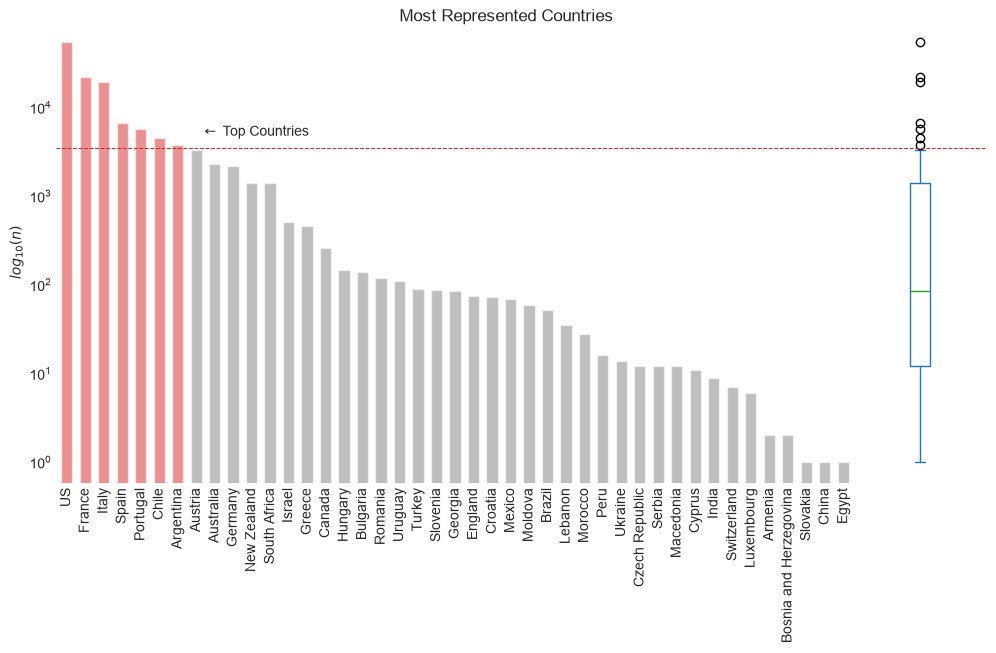

In [7]:
fig, ax = plt.subplot_mosaic("AAAAAAB", figsize=(12,6), sharey=True, gridspec_kw={"wspace": 0})

# Compute statistics
q3 = countries.quantile(.75)
iqr = q3 - countries.quantile(.25)
max_bar = q3 + 1.5 * iqr

# Apply to color
foreground_color = "tab:red"
background_color = "tab:gray"
colors = [foreground_color if val >= max_bar else background_color for val in countries]

# Draw bar and box plots
countries.plot.bar(ax=ax['A'], logy=True, legend=False, color=colors, width=.6, alpha=.5)
countries.plot.box(ax=ax['B'], logy=True)

# Draw outline cut-off line
ax['A'].axhline(max_bar, color=foreground_color, ls='--', lw=.75)
ax['B'].axhline(max_bar, color=foreground_color, ls='--', lw=.75)
ax['A'].text(.25, .75, "$\\leftarrow$ Top Countries", transform=ax['A'].transAxes, ha='center')

# Fix labels, ticks, and spines
ax['A'].set_ylabel("$log_{10}(n)$")
ax['A'].tick_params(axis='both', which='both', length=0)
ax['A'].set_xlabel("")
ax['A'].spines[['top', 'right', 'left', 'bottom']].set_visible(False)

ax['B'].spines[['left','bottom', 'top', 'right']].set_visible(False)
ax['B'].tick_params(axis='both', which='both', length=0)
ax['B'].set_xticklabels([])

plt.suptitle("Most Represented Countries", y=.9)

plt.show()

<div style="width:10in;font-size:110%;">
<b>Figure 1</b>: 
This histogram shows the log frequency of observations (reviews) by country.
The distribtion of country counts follows a classic power law distribution, and so it helps to show the series in the linear space of a logarithm. 
The box plot on the right shows where the outliers are. In this case, the outliers are the rule, not the exceptions.
They account for the vast majority of content in the dataset.
We use this information to truncate our dataset to include only those reviews that belong to the top 7 countries:
US, France, Italy, Spain, Portugal, Chile, and Argentina.
</div>

In [8]:
top_countries = countries[countries > max_bar].index.tolist()
top_countries

['US', 'France', 'Italy', 'Spain', 'Portugal', 'Chile', 'Argentina']

In [9]:
reviews_top = reviews.loc[reviews['country'].isin(top_countries)].copy()
reviews_top.shape

(116745, 8)

## Which tasters review which countries?

Let's use an alluvial to take a quick look.

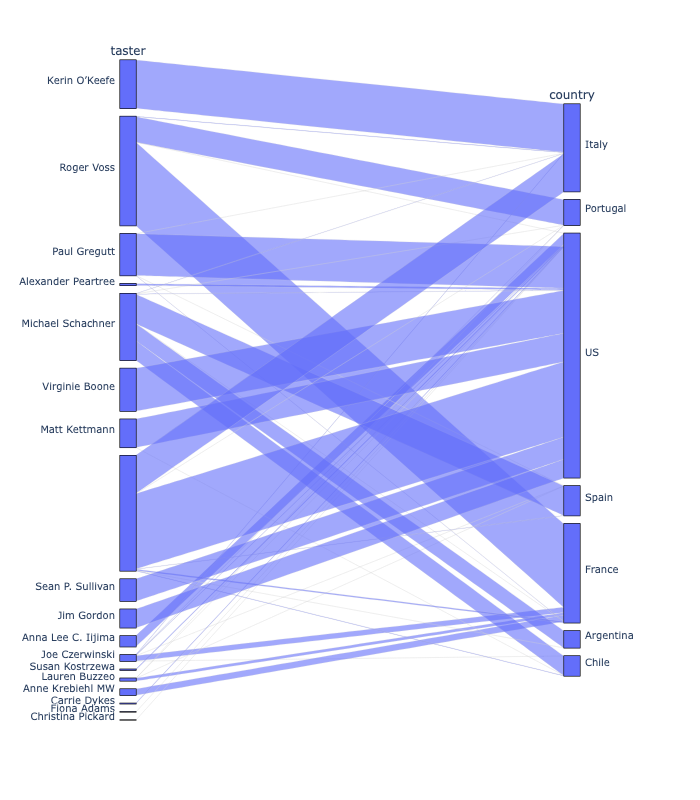

In [10]:
px.parallel_categories(reviews_top[['taster', 'country']], height=800)

Note that we can't assign a color to a variable since we haven't defined any categorical types.

Note also that there is a big chunk of unnamed tasters -- these do not show up in value counts unless you tell it show them.

In [11]:
reviews_top.taster.value_counts(dropna=False)

taster
NaN                   25720
Roger Voss            24359
Michael Schachner     14885
Kerin O’Keefe         10776
Virginie Boone         9537
Paul Gregutt           9345
Matt Kettmann          6332
Sean P. Sullivan       4934
Jim Gordon             4177
Anna Lee C. Iijima     2435
Joe Czerwinski         1413
Anne Krebiehl MW       1395
Lauren Buzzeo           619
Alexander Peartree      415
Susan Kostrzewa         232
Carrie Dykes            139
Fiona Adams              27
Christina Pickard         5
Name: count, dtype: int64

So, let's convert these nulls into 'Anonymous' make the column categorical.

In [12]:
reviews_top.loc[reviews_top.taster.isna(), 'taster'] = 'Anonymous'
reviews_top[['country', 'taster']] = reviews_top[['country', 'taster']].astype('category')

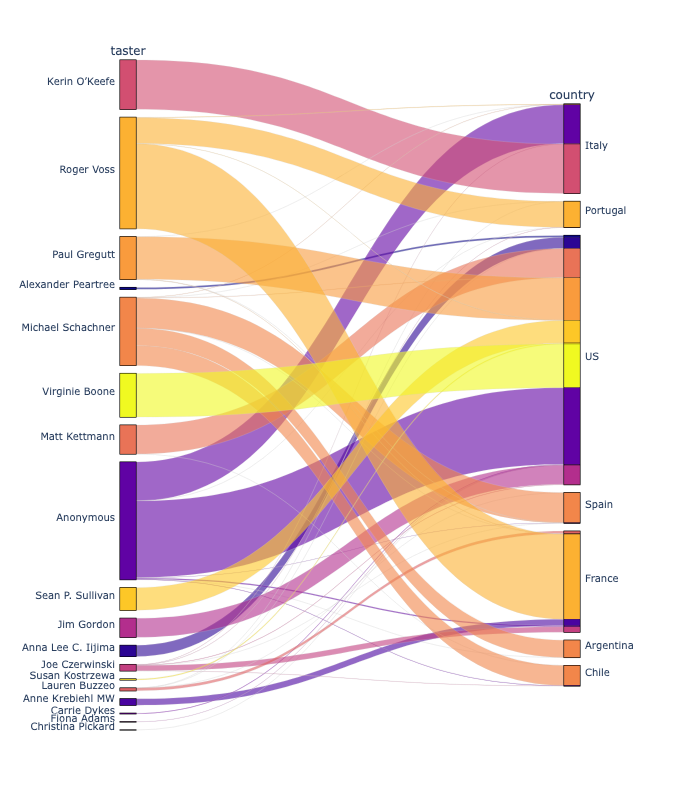

In [13]:
fig = px.parallel_categories(
    reviews_top, 
    dimensions=['taster', 'country'], 
    color=reviews_top.taster.cat.codes, 
    width=1000, height=800
)
fig.update_traces(line_shape='hspline')
fig.update_layout(coloraxis_showscale=False)
fig.show()

We can also view this as a heatmap.

In [14]:
country_taster = reviews_top.value_counts(['country','taster'])
country_taster = country_taster[country_taster > 0]
country_taster = country_taster.unstack(fill_value=0).T
country_taster.style.background_gradient(axis=None, cmap='YlGnBu')

country,Argentina,Chile,France,Italy,Portugal,Spain,US
taster,,,,,,,
Alexander Peartree,0,0,0,0,0,0,415
Anna Lee C. Iijima,0,0,0,0,0,0,2435
Anne Krebiehl MW,0,0,1395,0,0,0,0
Anonymous,3,111,265,8498,5,64,16774
Carrie Dykes,0,0,0,0,0,0,139
Christina Pickard,0,0,0,0,0,0,5
Fiona Adams,0,0,0,0,0,0,27
Jim Gordon,0,0,0,0,0,0,4177
Joe Czerwinski,0,23,1179,89,18,1,103


### Figure 2

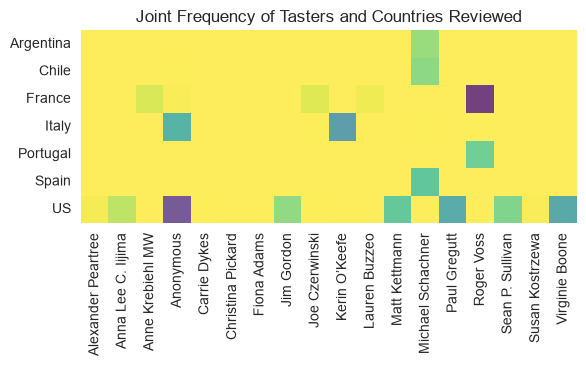

In [15]:
sns.heatmap(country_taster.T, cmap="viridis_r", square=True, alpha=.75, cbar=None)
plt.xlabel("")
plt.ylabel("")
plt.title("Joint Frequency of Tasters and Countries Reviewed")
plt.show()

<div style="width:7in;font-size:110%;">
<b>Figure 2</b>: This heatmap shows the distribution of tasters and countries of reviewed wines.
The darker squares show both prolific writing and heavy concentration in a particular area.
<i>Anonymous</i> accounts for a large percentage of interviews and concentrate in the US and Italy.
The most prolific taster is <i>Roger Voss</i>, who devotes most of his time to French and Portuguese wines.
</div>

Here look at summary statistics of countries and tasters.

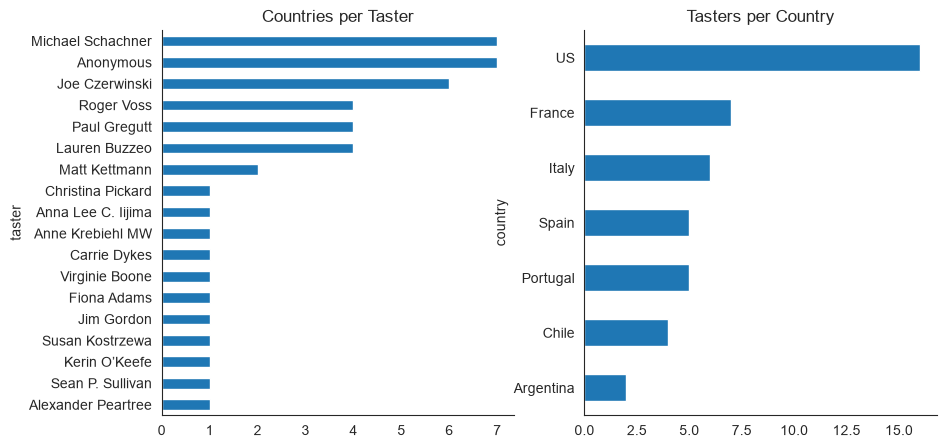

In [16]:
fig, ax = plt.subplot_mosaic("AB", figsize=(10, 5))
country_taster.astype(bool).sum().sort_values().plot.barh(title="Tasters per Country", ax=ax['B'])
country_taster.T.astype(bool).sum().sort_values().plot.barh(title="Countries per Taster", ax=ax['A'])
sns.despine()
plt.show()

## Comparing Price and Points

Let's compare price and points.

These two measures are related in that both assign value to the wine.

The first is assign by the market, the second by individual tasters.

It will be interesting to see how they are related.

First, let's prepare a separate dataframe for the two variables.

In [17]:
price_point = reviews_top[['price','points']].dropna().copy()
price_point['price'] = price_point['price'].astype(int)
price_point.head()

,price,points
obs_id,,
1,15,87
2,14,87
3,13,87
4,65,87
5,15,87


Even though both variables are numeric measurements, they also have a discrete quality that makes them suitable to be treated as categories.

It is often the case that numbers are used in this way, especially when they represent human assignments of value.

Given this, let's start off with a heatmap of their value counts.

In [18]:
ppvc = price_point.value_counts(['price','points']).sort_index().unstack(fill_value=0)
ppvc.head(50).style.background_gradient(axis=None, cmap="YlGnBu")

points,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100
price,,,,,,,,,,,,,,,,,,,,,
4,0,0,1,1,5,2,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,2,3,3,11,9,7,2,3,0,0,0,0,0,0,0,0,0,0,0,0,0
6,3,2,12,16,23,31,10,8,4,0,0,0,0,0,0,0,0,0,0,0,0
7,10,20,26,67,88,78,47,31,12,3,0,1,0,0,0,0,0,0,0,0,0
8,23,29,61,100,169,174,121,91,32,9,2,1,0,0,0,0,0,0,0,0,0
9,19,46,68,128,180,268,227,155,60,16,17,3,0,0,0,0,0,0,0,0,0
10,38,77,164,269,510,702,585,419,221,58,37,10,0,0,0,0,0,0,0,0,0
11,20,42,81,145,288,370,371,304,127,44,24,7,3,0,0,0,0,0,0,0,0
12,38,66,123,224,496,616,689,685,381,111,68,21,7,1,0,0,0,0,0,0,0


Viewed in this way, an interesting pattern is emerges: **prices cluster at 5 dollar intervals, forming bands in the heatmap.**

In addition, each band has a central value.

Taking advantage of this observation, we can produce a reduced representation of the heatmap showing only prices at 5 dollar intervals.

The result is a clear visualization of where the most wines are in price/point space. 

The most popular wine appears to be an $88$ point wine for $\$20$.

In [19]:
ppvc[ppvc.index % 5 == 0].head(20).style.background_gradient(axis=None, cmap="YlGnBu")

points,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100
price,,,,,,,,,,,,,,,,,,,,,
5,2,3,3,11,9,7,2,3,0,0,0,0,0,0,0,0,0,0,0,0,0
10,38,77,164,269,510,702,585,419,221,58,37,10,0,0,0,0,0,0,0,0,0
15,32,47,128,216,430,729,935,1096,818,393,363,104,30,4,0,0,0,0,0,0,0
20,18,27,100,166,339,512,700,1094,1123,691,706,358,157,47,18,4,1,0,0,0,0
25,12,19,63,110,228,340,456,783,940,607,778,457,292,81,23,7,0,0,0,0,0
30,8,12,39,61,146,242,369,606,712,533,683,537,345,162,44,10,3,0,0,0,0
35,1,8,27,38,100,139,237,381,501,409,586,472,324,192,65,13,1,1,0,0,0
40,7,1,22,28,80,104,212,378,469,376,557,490,456,263,93,29,6,1,0,0,0
45,2,4,13,21,46,69,120,251,349,340,484,421,423,253,129,38,8,1,0,0,0


Here's the same heatmap using Seaborn.

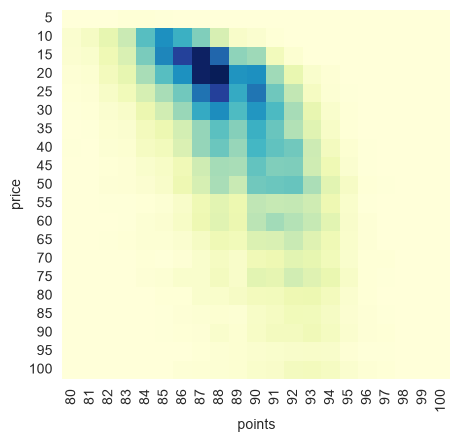

In [20]:
sns.heatmap(
    ppvc[ppvc.index % 5 == 0].head(20), 
    cmap='YlGnBu', 
    cbar=False, 
    square=True,
    # annot=True
)
plt.show()

Note that neither a histogram nor a density plot shows the pattern of five dollar clustering, at least not without doing a search across bin sizes.

In other words, if you rely solely on these plots for EDA, you might miss this important structural feature.

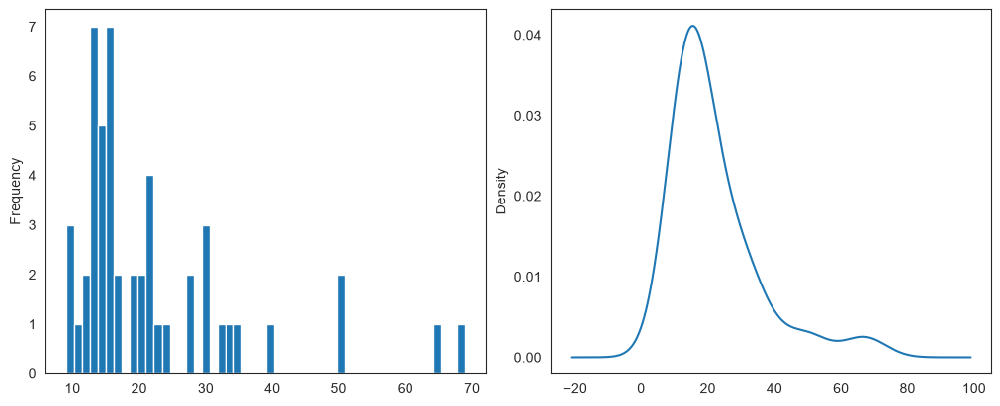

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10,4), layout='constrained')
price_point.head(50).price.plot.hist(ax=ax[0], bins=50)
price_point.head(50).price.plot.density(ax=ax[1])
plt.show()

### Figure 2a

Probably the best way to represent the clustering pattern in the prices is to use a bar chart.

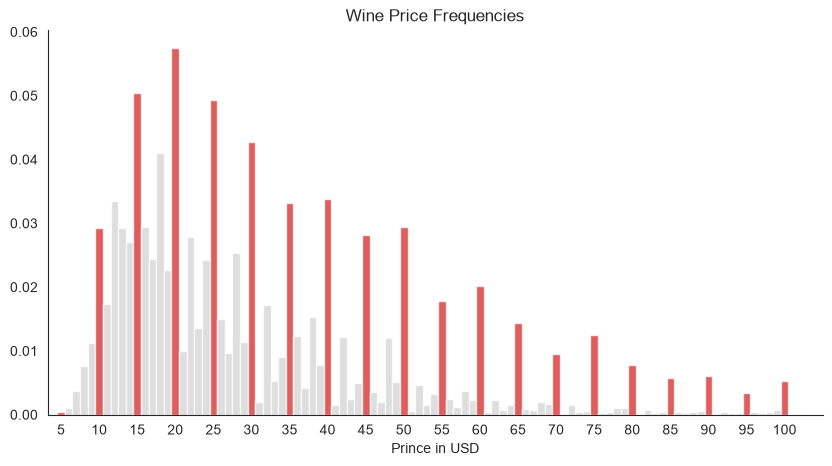

In [22]:
ppvc_short = price_point[price_point.price <= 100].value_counts('price', normalize=True).sort_index()
color = [('tab:red' if x % 5 == 0 else 'lightgray') for x in ppvc_short.index]
ax = ppvc_short.plot.bar(figsize=(10,5), rot=0, color=color, width=1, alpha=.75)
plt.xticks(np.arange(1, 100 + 5, step=5))
sns.despine()
plt.title("Wine Price Frequencies")
plt.xlabel("Prince in USD")
plt.show()

<div style="font-size:110%; width:9in;">
    <b>Figure 2a</b>: The bar chart above shows that wine prices cluster at five dollar intervals. 
    This pattern represents a prefence among sellers of wine, which may in turn their perceptions of price points that will appeal most to buyers. The most frequent price is $20.
</div>

At $20, here are is the distribution of points.

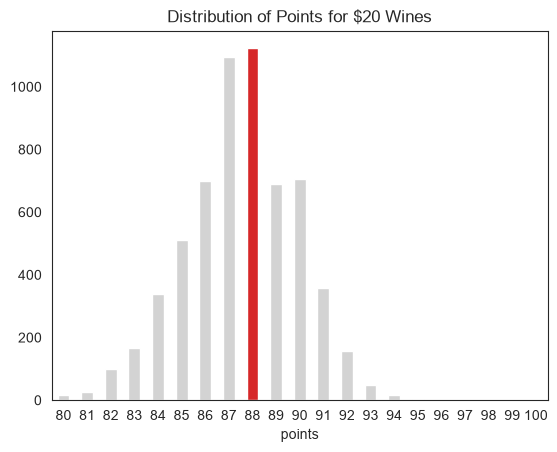

In [23]:
price = 20
S = ppvc.loc[price]
ax = S.plot.bar(rot=0, color=[('tab:red' if x == S.idxmax() else 'lightgray') for x in S.index])
plt.title("Distribution of Points for $20 Wines")
plt.show()

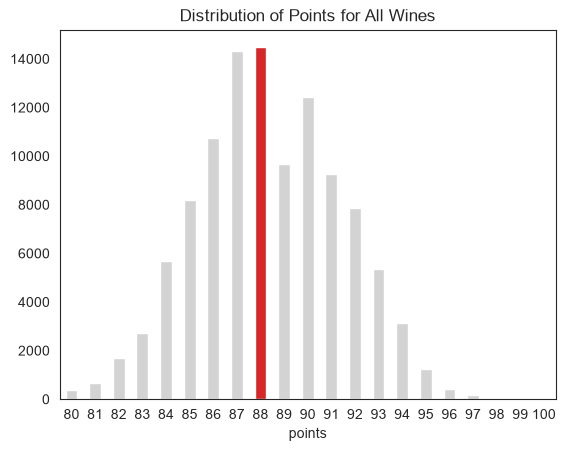

In [24]:
ppvc.sum().plot.bar(
    rot=0, 
    color=[('tab:red' if x == ppvc.sum().idxmax() else 'lightgray') for x in ppvc.sum().index],
    title="Distribution of Points for All Wines"
)
plt.show()

## Does price predict points?

Now let's explore the functional relationship between the two variables.

In particular, can we use price to predict points? 

Or does the market not always get it right?

Let's look at the relationship between price and points first.

Here, we use a scatterplot, treating the two series of integers as floats.

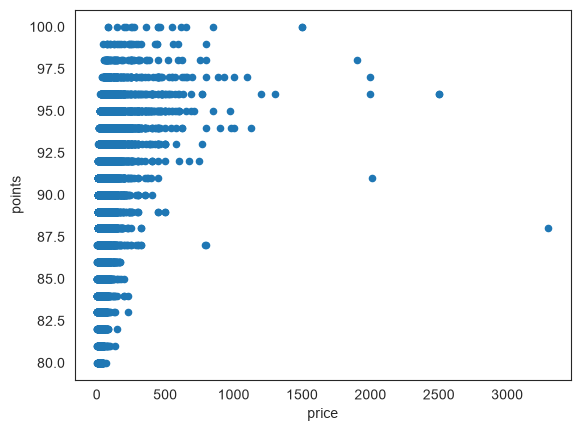

In [25]:
price_point.plot.scatter('price', 'points', color='tab:blue')
plt.show()

Here we see a classic tornado pattern. 

This implies that a lot of data is concentrated at one end of the x axis.

We can spread the crowded data points out by showing the x axis on a **log scale.**

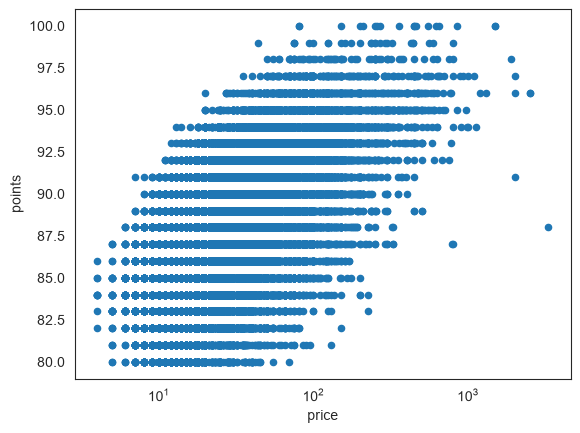

In [26]:
price_point.plot.scatter('price', 'points', logx=True, color='tab:blue')
plt.show()

Here we see that the there is a linear relationship between the two variables with a great deal of variance.

This variance is probably due to the market, the constant game of cat and mouse between seller and buyer, producer and consumer.

Let's model this relationship and then use it as a tool later.

In [27]:
price_point['price_log'] = price_point['price'].apply(np.log10)
m, b = np.polyfit(price_point.price_log, price_point.points, 1)
price_point['pp_model'] = (price_point.price_log * m + b)
price_point

,price,points,price_log,pp_model
obs_id,,,,
1,15,87,1.176091,86.578223
2,14,87,1.146128,86.378822
3,13,87,1.113943,86.164638
4,65,87,1.812913,90.816175
5,15,87,1.176091,86.578223
...,...,...,...,...
129965,28,90,1.447158,88.382130
129967,75,90,1.875061,91.229760
129968,30,90,1.477121,88.581531


### Figure 3

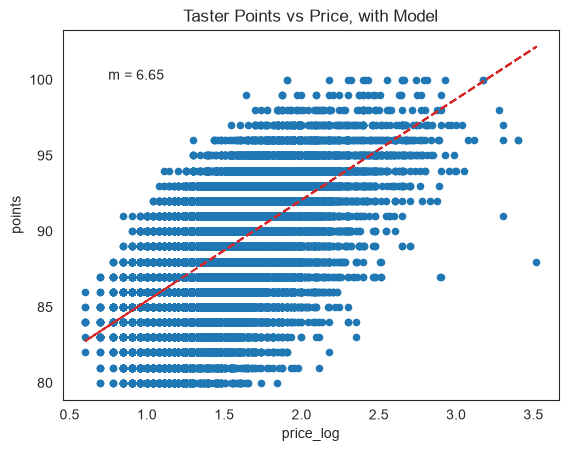

In [28]:
ax = price_point.plot.scatter('price_log', 'points', color='tab:blue')
price_point.plot(x='price_log', y='pp_model', ax=ax, color='tab:red', ls='--', legend=False)
ax.text(.75, 100, "m = 6.65")
plt.title("Taster Points vs Price, with Model")
plt.show()

<div style="font-size:110%; width:6in;">
<b>Figure 3</b>: This scatterplot of the log of the price versus taster points shows an upward bias.
The line is a crude linear model of the rate by which points increase with price.
According to the model, for evey unit increase in the log of price, the points go up by <tt>6.65</tt>.
The plot shows that there are many overpriced and underpriced wines &mdash; i.e. wines to avoid and wines to buy.
</div>

## Where are the bargain wines?

Let's say that a bargain wine is one that meets the following criteria:

- Punches above its weight class, i.e. points **above the model line**.
- Is affordable, i.e. is at or **below the median price**.
- Is good, i.e. at or **above the median points**.

In [29]:
median_price = price_point.price.median()
median_price_log = price_point.price_log.median()
median_points = price_point.points.median()
print(f"Median price:\t{median_price.astype(int)}\nMedian pionts:\t{median_points.astype(int)}")

Median price:	26
Median pionts:	88


Note these value correspond closely to the most popular combo of price and points we discovered in the heatmap above.

### Figure 4

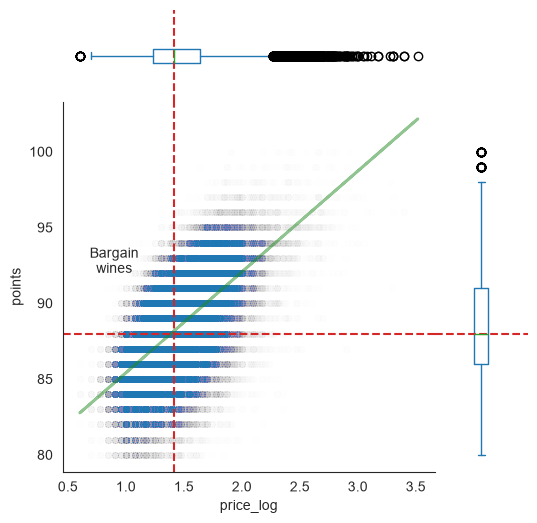

In [30]:
fig, ax = plt.subplot_mosaic(
    "A.;BC", 
    figsize=(6,6), 
    gridspec_kw = {
        "wspace": .0,  
        "hspace": .0,
        "width_ratios": [4, 1],  
        "height_ratios": [1, 4], 
    }
)

# Main scatter
price_point.plot.scatter('price_log', 'points', alpha=.005, ax=ax['B'])

# Marginal box plots
price_point['price_log'].plot.box(vert=False, ax=ax['A'])
price_point['points'].plot.box(ax=ax['C'])

# Model line
price_point.plot(x='price_log', y='pp_model', color='forestgreen', lw=2, alpha=.5, legend=False, ax=ax['B'])

ax["C"].sharey(ax["B"])

ax['A'].spines[['left','bottom', 'top', 'right']].set_visible(False)
ax['A'].tick_params(axis='both', which='both', length=0)
ax['A'].set_xticklabels([])
ax['A'].set_yticklabels([])

ax['B'].spines[['top', 'right']].set_visible(False)

ax['B'].axvline(median_price_log, color='tab:red', ls='--')
ax['A'].axvline(median_price_log, color='tab:red', ls='--')
ax['B'].axhline(median_points, color='tab:red', ls='--')
ax['C'].axhline(median_points, color='tab:red', ls='--')

ax['C'].spines[['left','bottom', 'top', 'right']].set_visible(False)
ax['C'].tick_params(axis='both', which='both', length=0)
ax['C'].set_xticklabels([])
ax['C'].tick_params(axis='y', left=False, labelleft=False)


ax['B'].text(.9, 92, "Bargain\nwines", ha='center')


plt.show()

<div style="font-size:110%; width:5in;">
<b>Figure 4</b>: This scatterplot shows the relationship between log price, points, and a regression model.
The reduced opactity of the points, along with the box plots for each axis show a different concentraton of data.
At the lower end of price, wines tend to be below the model (i.e. bad buys)
whereas at the upper end of price they tend to be above the model (i.e. good buys).
By overlaying the median values of points and log price we can define a region where the bargain wines live.
As it turns out, we don't need the model to define this region: the medians will do.
</div>

Let's just buy wine that is above the median in points and below the median in price.

In [31]:
price_point['bargain'] = False
price_point.loc[
    (price_point.price_log <= median_price) 
    & (price_point.points > median_points), 'bargain'] = True

info_cols = ['country', 'variety', 'title']
bargains = price_point[price_point.bargain == True].sort_values('points', ascending=False).join(reviews[info_cols])
print(f"N = {len(bargains):,}")
bargains.head()

N = 49,654


,price,points,price_log,pp_model,bargain,country,variety,title
obs_id,,,,,,,,
118058,450,100,2.653213,96.408236,True,US,Bordeaux-style Red Blend,Verité 2007 La Muse Red (Sonoma County) La Mu...
122935,848,100,2.928396,98.239538,True,France,Bordeaux-style White Blend,Château Haut-Brion 2014 Pessac-Léognan (Bor...
45781,550,100,2.740363,96.988207,True,Italy,Sangiovese,Biondi Santi 2010 Riserva (Brunello di Monta...
42197,450,100,2.653213,96.408236,True,Portugal,Portuguese Red,Casa Ferreirinha 2008 Barca-Velha Red (Douro)...
45798,200,100,2.301030,94.064516,True,US,Cabernet Sauvignon,Cardinale 2006 Cabernet Sauvignon (Napa Valle...


## Best bang for you buck?

What about wines that are not necessarily above the model line, but which have a high ratio of points to price?

This would be decent wines at a very low price.

Let's call this the "bang for you buck index", or $BBI$.

$$
BBI = \dfrac{\text{points}}{\text{price}}
$$

In [32]:
price_point['bbi'] = (price_point.points / price_point.price).round(2)

Look at the distribution of BBI.

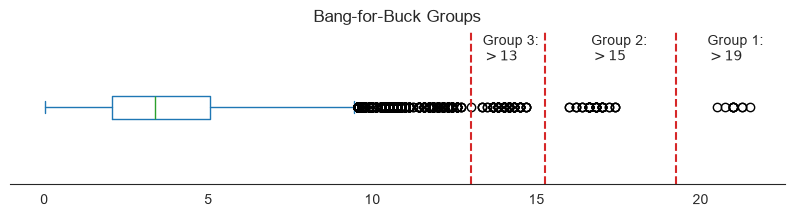

In [33]:
ax = price_point.bbi.plot.box(figsize=(10,2), vert=False)

# Group 1
ax.axvline(19.25, color='tab:red', ls='--')
ax.text(.9, .8, "Group 1:\n$>19$", transform=ax.transAxes)

# Group 2
ax.axvline(15.25, color='tab:red', ls='--')
ax.text(.75, .8, "Group 2:\n$>15$", transform=ax.transAxes)

# Group 3
ax.axvline(13, color='tab:red', ls='--')
ax.text(.61, .8, "Group 3:\n$>13$", transform=ax.transAxes)

plt.yticks([])
plt.title("Bang-for-Buck Groups")

sns.despine(left=True)

plt.show()

In [34]:
price_point['bbi_g1'] = price_point.bbi > 19

bbi_g1 = price_point[price_point.bbi_g1 == True].sort_values('points', ascending=False).join(reviews[info_cols])
print("N =", len(bbi_g1))
bbi_g1.head()

N = 10


,price,points,price_log,pp_model,bargain,bbi,bbi_g1,country,variety,title
obs_id,,,,,,,,,,
64590,4,86,0.60206,82.758134,False,21.50,True,US,Merlot,Bandit NV Merlot (California) (Merlot) by
1987,4,85,0.60206,82.758134,False,21.25,True,Spain,Syrah,Felix Solis 2013 Flirty Bird Syrah (Vino de l...
20484,4,85,0.60206,82.758134,False,21.25,True,US,White Blend,Dancing Coyote 2015 White (Clarksburg) (Whit...
29553,4,84,0.60206,82.758134,False,21.00,True,Argentina,Malbec-Syrah,Broke Ass 2009 Red Malbec-Syrah (Mendoza) Red...
31530,4,84,0.60206,82.758134,False,21.00,True,US,Chardonnay,Bandit NV Chardonnay (California) (Chardonna...


In [35]:
price_point['bbi_g2'] = (price_point.bbi > 15) & (price_point.bbi <= 19)

bbi_g2 = price_point[price_point.bbi_g2 == True].sort_values('points', ascending=False).join(reviews[info_cols])
print("N =", len(bbi_g2))
bbi_g2.head()

N = 40


,price,points,price_log,pp_model,bargain,bbi,bbi_g1,bbi_g2,country,variety,title
obs_id,,,,,,,,,,,
104412,5,87,0.69897,83.403055,False,17.4,False,True,US,Sparkling Blend,Mancan NV Fizz Sparkling (California) Fizz (S...
62072,5,87,0.69897,83.403055,False,17.4,False,True,Chile,Sauvignon Blanc,In Situ 2008 Reserva Sauvignon Blanc (Aconcag...
24592,5,87,0.69897,83.403055,False,17.4,False,True,Chile,Sauvignon Blanc,In Situ 2008 Reserva Sauvignon Blanc (Aconcag...
3167,5,86,0.69897,83.403055,False,17.2,False,True,Italy,Glera,Anna Spinato NV Mini (Prosecco) Mini (Glera)...
69658,5,86,0.69897,83.403055,False,17.2,False,True,US,Merlot,Earth's Harvest 2013 Merlot (California) (Me...


In [36]:
price_point['bbi_g3'] = (price_point.bbi > 12) & (price_point.bbi <= 15)

bbi_g3 = price_point[price_point.bbi_g3 == True].sort_values('points', ascending=False).join(reviews[info_cols])
print("N =", len(bbi_g3))
bbi_g3.head()

N = 281


,price,points,price_log,pp_model,bargain,bbi,bbi_g1,bbi_g2,bbi_g3,country,variety,title
obs_id,,,,,,,,,,,,
34629,7,91,0.845098,84.375514,True,13.00,False,False,True,Portugal,Portuguese Red,Herdade dos Machados 2012 Toutalga Red (Alent...
95728,7,89,0.845098,84.375514,True,12.71,False,False,True,Portugal,Portuguese Red,Caves Velhas 2013 D. Fuas Reserva Red (Terras...
63697,7,89,0.845098,84.375514,True,12.71,False,False,True,US,Red Blend,Hogue 2008 Red Table Wine Red (Columbia Valle...
42891,7,89,0.845098,84.375514,True,12.71,False,False,True,Spain,Garnacha,Borsao 2008 Monte Oton Garnacha (Campo de Bor...
122481,7,88,0.845098,84.375514,False,12.57,False,False,True,Portugal,Portuguese White,Caves da Montanha 2014 Trinca Espinhas Alvari...


## Yet another method: Cheapest in class

The best wines for \$100 or less.

In [37]:
price_point['cic'] = (price_point.price <= 100) & (price_point.points >= 90)
cic = price_point[price_point.cic == True].sort_values(['points', 'price'], ascending=[False, True]).join(reviews[info_cols])
print(f"N = {len(cic):,}")
cic.head()

N = 37,211


,price,points,price_log,pp_model,bargain,bbi,bbi_g1,bbi_g2,bbi_g3,cic,country,variety,title
obs_id,,,,,,,,,,,,,
113929,80,100,1.903090,91.416287,True,1.25,False,False,False,True,US,Syrah,Charles Smith 2006 Royal City Syrah (Columbia...
123545,80,100,1.903090,91.416287,True,1.25,False,False,False,True,US,Syrah,Cayuse 2008 Bionic Frog Syrah (Walla Walla Va...
118059,44,99,1.643453,89.688440,True,2.25,False,False,False,True,US,Chardonnay,Failla 2010 Estate Vineyard Chardonnay (Sonom...
47428,75,99,1.875061,91.229760,True,1.32,False,False,False,True,US,Syrah,Cayuse 2009 En Chamberlin Vineyard Syrah (Wal...
47429,75,99,1.875061,91.229760,True,1.32,False,False,False,True,US,Pinot Noir,Williams Selyem 2010 Hirsch Vineyard Pinot No...


## Which countries have the best buys?

In [38]:
bbi_min = bargains.price.min()
bbi_max = bargains.price.max()
cic_min = cic.price.min()
cic_max = cic.price.max()

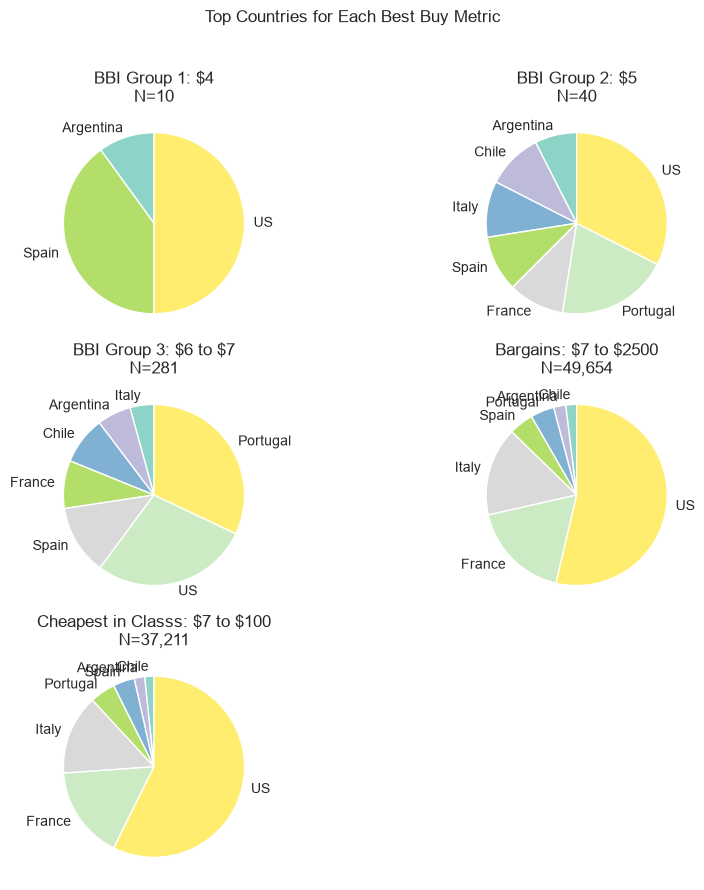

In [39]:
fig, ax = plt.subplot_mosaic("AB;CD;E.", figsize=(10,10))
config = {
    'kind': 'pie',
    'cmap': 'Set3',
    'startangle': 90
}
bbi_g1.value_counts('country').sort_values().plot(**config, ax=ax['A'], title=f"BBI Group 1: \\$4\nN={len(bbi_g1)}")
bbi_g2.value_counts('country').sort_values().plot(**config, ax=ax['B'], title=f"BBI Group 2: \\$5\nN={len(bbi_g2)}")
bbi_g3.value_counts('country').sort_values().plot(**config, ax=ax['C'], title=f"BBI Group 3: \\$6 to \\$7\nN={len(bbi_g3)}")
bargains.value_counts('country').sort_values().plot(**config, ax=ax['D'], title=f"Bargains: \\${bbi_min} to \\${bbi_max}\nN={len(bargains):,}")
cic.value_counts('country').sort_values().plot(**config, ax=ax['E'], title=f"Cheapest in Classs: \\${cic_min} to \\${cic_max}\nN={len(cic):,}")

plt.suptitle("Top Countries for Each Best Buy Metric")
plt.show()

We create a function to pop out wedges from the pie.

In [40]:
def get_popper(l, x):
    return [(.05 if c == x else 0) for c in l] 

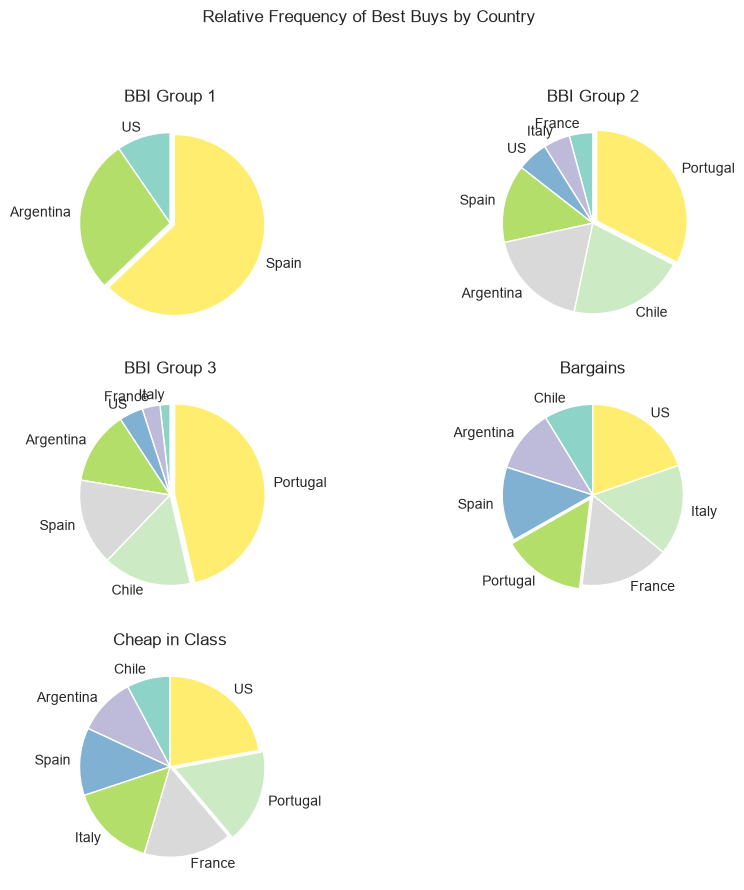

In [41]:
fig, ax = plt.subplot_mosaic("AB;CD;E.", figsize=(10,10))
config = {
  'kind': 'pie',
  'cmap': 'Set3',
  'startangle': 90    
}

pie1 = (bbi_g1.value_counts('country') / countries).sort_values().dropna()
pie1.plot(
    **config, 
    ax=ax['A'], 
    title='BBI Group 1',
    explode=get_popper(pie1.index, 'Spain')
)
pie2 = (bbi_g2.value_counts('country') / countries).sort_values().dropna()
pie2.plot(
    **config,
    ax=ax['B'], 
    title='BBI Group 2',
    explode=get_popper(pie2.index, 'Portugal')
)
pie3 = (bbi_g3.value_counts('country') / countries).sort_values().dropna()
pie3.plot(
    **config,
    ax=ax['C'],
    title='BBI Group 3',
    explode=get_popper(pie3.index, 'Portugal')
)
pie4 = (bargains.value_counts('country') / countries).sort_values().dropna()
pie4.plot(
    **config,
    ax=ax['D'], 
    title='Bargains',
    explode=get_popper(pie4.index, 'Portugal')
)
pie5 = (cic.value_counts('country') / countries).sort_values().dropna()
pie5.plot(
    **config,
    ax=ax['E'], 
    title='Cheap in Class',
    explode=get_popper(pie5.index, 'Portugal')    
)

for my_ax in ax.values():
    my_ax.set_ylabel(None)
    my_ax.spines[['top','right','left','bottom']].set_visible(False)
    my_ax.set_xticks([])

plt.ylabel(None)
plt.suptitle("Relative Frequency of Best Buys by Country")

plt.show()

<div style="font-size:110%; width:7in;">
        <b>Figure</b>: The pie charts above show which countries tend to produce the best buys.
    Although not the most frequent wine in the best buy categories, 
<i>Portugal</i> emerges as a country from which a relatively high percentage of wines are a good buy.
In the Bang-for-Buck Group 1, <i>Spain</i> is the king.    

</div>

Actually, the figure above is an example of an inapprpriate use of the pie chart.

The reason is that the values, as relative frequencies, do not sum up to anything meaningful.

Since we want to compare magnites, not inspect composition, a better tool here is the bar chart.

### Figure 5

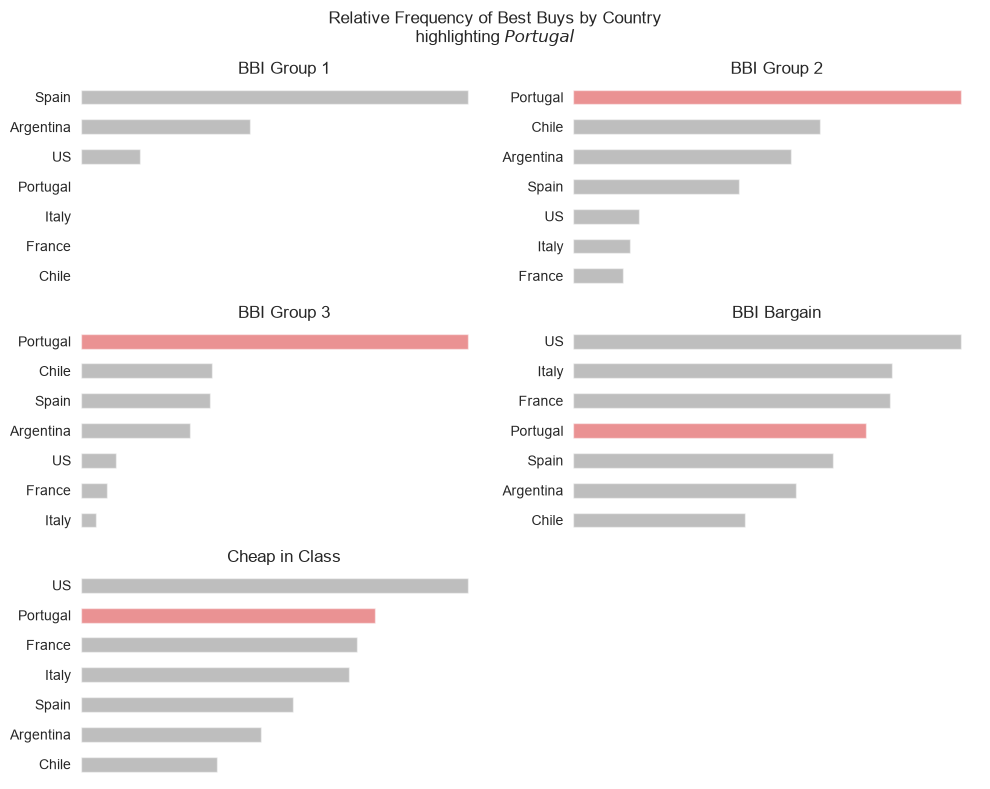

In [42]:
metrics = dict(
    bbi_g1 = "BBI Group 1",
    bbi_g2 = "BBI Group 2",
    bbi_g3 = "BBI Group 3", 
    bargain = "BBI Bargain", 
    cic = "Cheap in Class",
)

fig, ax = plt.subplot_mosaic([
    ['bbi_g1', 'bbi_g2'], 
    ['bbi_g3', 'bargain'], 
    ['cic', '.']
], figsize=(10,8))

for metric in metrics.keys():
    df = price_point[price_point[metric] == True].sort_values('points', ascending=False).join(reviews[info_cols])
    freq = (df.value_counts('country') / countries.loc[top_countries]).fillna(0).sort_values()
    freq.plot(
        ax=ax[metric], 
        title=metrics[metric],
        color = ['tab:red' if x == 'Portugal' else 'tab:gray' for x in freq.index],
        kind='barh',
        alpha= .5
    )

for my_ax in ax.values():
    my_ax.set_ylabel(None)
    my_ax.spines[['top','right','left','bottom']].set_visible(False)
    my_ax.set_xticks([])
    
plt.ylabel(None)
plt.suptitle("Relative Frequency of Best Buys by Country\nhighlighting $Portugal$")
plt.tight_layout()

plt.show()

<div style="font-size:110%; width:9in;">
    <b>Figure 5</b>: The bar charts above show which countries tend to produce the best buys. The bars show relative frequencies, computed by dividing the number of wines from a country for a best buy category by the total number of wines for the country.
The resulting numbers are very small and so are not listed; what matters are the relative proportions. 
Although not the most frequent wine in the best buy categories, 
<i>Portugal</i> emerges as a country from which a relatively high percentage of wines are a good buy.
In the Bang-for-Buck Group 1, <i>Spain</i> is the king.    
</p>

## Looking at all of it

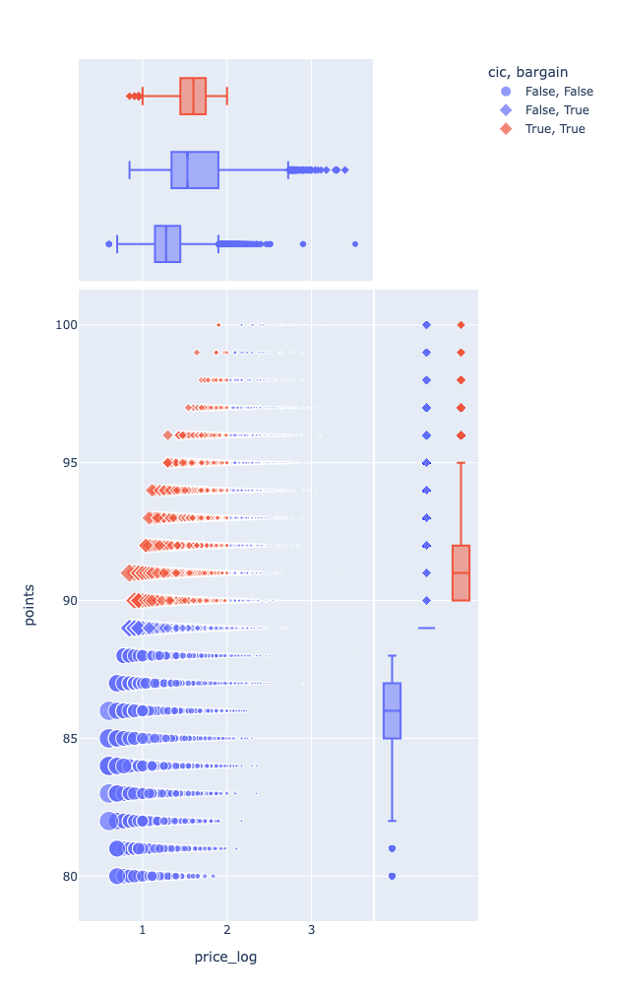

In [43]:
px.scatter(
    price_point.join(reviews_top[info_cols]), 
    x='price_log', y='points', 
    color='cic', 
    symbol='bargain',
    size='bbi', 
    hover_name='title',
    height=1000, width=1200, 
    marginal_x='box', marginal_y='box'
)

This interactive plot shows all the things we looked at above.

One interesting thing that falls out is that the blue diamonds, i.e. wines that are bargains and yet not best in class, constitute only one one line of data &mdash; at $89$ points.

The reason they are not cheapest in class is because we arbitrarily drew the line at $90$ for that metric.

What this shows is that there are no bargain wines below $89$.

This causes us to realize that it might be a good idea to visualize the distribution of price and points for each of our metrics.